# Session 7, land-surface track: soil water in a model of the western United States

🖥️ Model & simulation · 💧 Land water · 💧 Hydrology & land-surface modeling

**Guiding question.** When and where does soil water in the western United States fall into drought, and how much of that does precipitation alone explain?

**Learning outcomes.** After this session you can:

1. Trace a gridded soil-water product back to what was measured, and say what the model added.
2. Show that a downloaded file is complete and unmodified, and explain why it may differ from an earlier copy.
3. Read a model grid: axis order, longitude convention, units, missing values, cells that cannot be right.
4. Tell a real climate extreme from an error in soil-water data.
5. Measure how data problems bias a drought frequency, and name those that cleaning cannot undo.
6. Set up drought classification on the grid without leaking test data into training.
7. Write rules and instructions that let another person, or an AI tool, rerun your chain from the PSL files to the drought frequency, and check whether it did.

**Objectives for today.** You will:

| Part | What you do | Rough time (min) |
|---|---|---|
| 0 | Predict when the model's soil bucket is fullest near Spokane | 3 |
| 1 | Download the Climate Prediction Center (CPC) model output from NOAA and check it | 10 |
| 2 | Read one model cell near Spokane as a table: limits, a real extreme, an error | 8 |
| 3 | Read its time series and the frozen-soil gaps of a station's probes | 8 |
| 4 | Map the grid and find the cells that cannot be right | 8 |
| 5 | Hunt five problems planted in a synthetic copy and measure their effect on drought frequency | 15 |
| 6 | Correlate precipitation with soil water, and test the model against the station | 8 |
| 7 | Write the steps from raw file to a training table for drought classification | 10 |
| 8 | Give an AI tool the same synthetic file; start your instructions for it | 7 |
| Wrap-up | Three answers and the summary | 3 |

The times are rough estimates of how long each part takes, not a schedule. Each question has a self-check and, below it, a hidden worked solution. Parts 4 and 8 are optional; skip them if you want more time for Part 5.

**Setup.** Work in your own copy (replace `UWNETID`), opened from `book/Chapter2-DataManipulation`; do not commit, push or stash.

    cd mlgeo-book
    git pull
    cp book/Chapter2-DataManipulation/lab_s07_land_surface_model.ipynb book/Chapter2-DataManipulation/lab_s07_land_surface_model_UWNETID.ipynb
    pixi run jupyter lab

**Submit** by Friday 16 October, 9:00 (see the end). Completion only: the work does not count toward your grade, but a missing submission costs 10 points.

**Not using `git pull`?** Download this track as one zip, [lab_s07_land_surface_model.zip](https://geo-smart.github.io/mlgeo-book/downloads/lab_s07_land_surface_model.zip), unzip it and open the notebook from the unzipped folder; the [start page](lab_s07_start_here.md) explains how.

In [1]:
# Setup: run this cell first.
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

import lab_s07_lsm_checks as chk
import lab_s07_lsm_synthetic as lab

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 120)

NETID = ""          # your UW NetID in quotes, for example "jdoe2": it chooses your synthetic twin in Part 5

for f in (lab.GRID_FILE, lab.STATIC_FILE, lab.TABLE_FILE, lab.PROV_FILE, lab.USCRN_FILE, lab.MAP_FILE):
    assert f.exists(), f"missing {f}: open this notebook from mlgeo-book/book/Chapter2-DataManipulation and git pull"
print("course copies in", lab.where(lab.SNAP))
print("downloads", "off (offline mode)" if lab.offline() else "allowed")
print("your files go to", lab.where(lab.output_dir()))
print("NetID:", NETID or "not set; Part 5 will use the class seed")

course copies in snapshots
downloads off (offline mode)
your files go to (temporary folder of the book build)/mlgeo_s07_lsm
NetID: not set; Part 5 will use the class seed


## Part 0. The system and the question (about 3 min)

**What to do:** read, run the map, predict.

Soil water is the store between the sky and the rivers: precipitation fills it; evaporation, transpiration, runoff and drainage empty it. Months of low soil water dry out crops and rangeland and lengthen the fire season: agricultural drought. No instrument measures the whole root zone across the West. Satellites (the Soil Moisture and Ocean Salinity mission since 2009, the Soil Moisture Active Passive mission since 2015) see the top 5 cm or so in footprints of about 40 km ([NASA](https://smap.jpl.nasa.gov/mission/description/); Entekhabi et al., 2010; Kerr et al., 2010). Point sensors, such as the U.S. Climate Reference Network (USCRN) station near Spokane (Part 2), reach a metre deep but sample a few square metres.

So NOAA's Climate Prediction Center computes soil water with "a one-layer hydrological model (Huang et al., 1996; van den Dool et al, 2003). The model takes observed precipitation and temperature and calculates soil moisture, evaporation and runoff" ([CPC](https://www.cpc.ncep.noaa.gov/soilmst/descrip.htm)). The layer holds at most 760 mm, a 1.6 m column at a porosity of 0.47. Each cell is a leaky bucket (van den Dool et al., 2003):

$$\frac{dW}{dt} = P - E - R - G,$$

with $W$ the soil water (mm), $P$ precipitation, $E$ evaporation (its potential rate computed from air temperature), $R$ runoff and $G$ loss to groundwater. The model has no snowpack (Arevalo et al., 2021): snow enters the soil in the month it falls. NOAA's Physical Sciences Laboratory (PSL) serves the monthly output on a 0.5 degree grid (Fan and van den Dool, 2004).

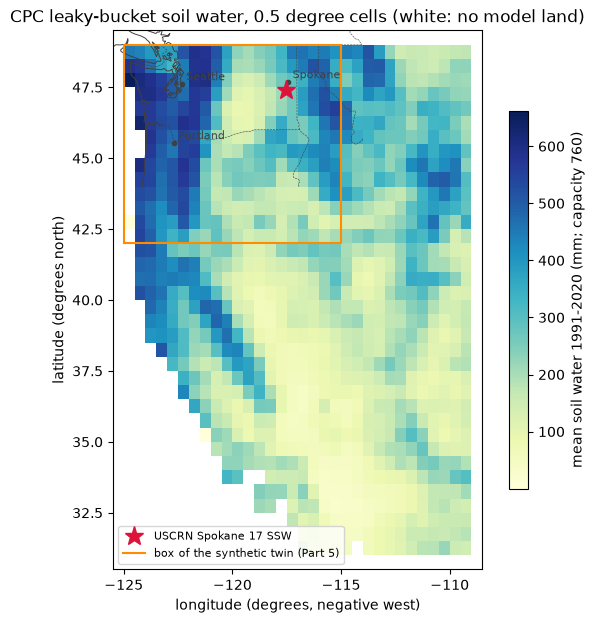

Map lines (Natural Earth) cover the Pacific Northwest only; farther south the edge of the coloured cells is the model's coastline.
992 cells with model soil water, 360 months from 1991-01 to 2020-12


In [2]:
grid = lab.open_grid()                         # the course copy: soil water and precipitation, 1991-2020
static = xr.open_dataset(lab.STATIC_FILE).load()
st_lat, st_lon = lab.spokane_station()         # USCRN Spokane 17 SSW, from NCEI's station list

mean_soil = grid["soilw"].mean("time")
fig, ax = plt.subplots(figsize=(7, 7))
pc = ax.pcolormesh(grid["lon"] - 360, grid["lat"], mean_soil, cmap="YlGnBu", shading="nearest")
fig.colorbar(pc, ax=ax, shrink=0.7, label="mean soil water 1991-2020 (mm; capacity 760)")
lab.draw_map(ax)
ax.plot(st_lon, st_lat, marker="*", color="crimson", ms=14, ls="none", label="USCRN Spokane 17 SSW")
x0, x1 = lab.SYN_LON[0] - 360, lab.SYN_LON[1] - 360
ax.plot([x0, x1, x1, x0, x0], [lab.SYN_LAT[0], lab.SYN_LAT[0], lab.SYN_LAT[1], lab.SYN_LAT[1], lab.SYN_LAT[0]],
        color="darkorange", lw=1.5, label="box of the synthetic twin (Part 5)")
ax.set_xlim(-125.5, -108.5); ax.set_ylim(30.5, 49.5)
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
ax.set_xlabel("longitude (degrees, negative west)"); ax.set_ylabel("latitude (degrees north)")
ax.set_title("CPC leaky-bucket soil water, 0.5 degree cells (white: no model land)")
ax.set_xticks(range(-125, -108, 5))
ax.legend(loc="lower left", fontsize=8)
plt.show()
print("Map lines (Natural Earth) cover the Pacific Northwest only; farther south the edge of the coloured cells is the model's coastline.")
print(f"{int(grid['soilw'].notnull().any('time').sum())} cells with model soil water, "
      f"{grid.sizes['time']} months from {str(grid.time.values[0])[:7]} to {str(grid.time.values[-1])[:7]}")

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Q0. Predict.** Near Spokane, winters are wet and summers dry and warm. In which calendar month (1 to 12) is the bucket fullest, on average?

In [3]:
q0_peak_month = None       # an integer from 1 to 12
chk.check("q0_peak_month", q0_peak_month)

not answered yet


In [4]:
# Worked solution, open after you tried
t = pd.read_csv(lab.TABLE_FILE)
clim = t.groupby(pd.to_datetime(t["month"]).dt.month)[["soilw_mm", "precip_mm_per_day"]].mean()
print(clim.round(2))
print("fullest month:", clim["soilw_mm"].idxmax(), "| emptiest month:", clim["soilw_mm"].idxmin())
chk.check_worked("q0_peak_month", int(clim["soilw_mm"].idxmax()))
# Precipitation peaks in November to January, but the bucket fills until April: potential evaporation comes
# from air temperature, is near zero while the monthly mean is near or below 0 degC (December to February
# here) and stays below precipitation until spring. From May on, evaporation wins. The model has no snowpack
# (Arevalo et al., 2021), so snow enters the bucket in the month it falls; real soil under snow fills at melt.

       soilw_mm  precip_mm_per_day
month                             
1        239.80               1.59
2        258.65               1.34
3        270.11               1.47
4        272.65               1.19
5        262.28               1.22
6        240.96               0.97
7        200.32               0.37
8        162.29               0.36
9        140.67               0.56
10       143.99               1.15
11       170.31               1.82
12       207.60               1.90
fullest month: 4 | emptiest month: 9
correct


```{admonition} If you are stuck
:class: hint
- `ModuleNotFoundError: lab_s07_lsm_synthetic`: open the notebook from `book/Chapter2-DataManipulation`, where the helper modules are.
- `NameError` in any cell: run the setup cell first.
```

## Part 1. Download the raw data and check it (about 10 min)

**What to do:** start the download, compare with the course copy, native resolution.

### 1a. Download from the provider

PSL serves soil water and the precipitation that drives the model (PREC/L, CPC's PRECipitation REConstruction over Land; Chen et al., 2002) as global files from 1948 to last month. PSL's subset service refused every request while this lab was built, so the cell downloads the whole global files (about 545 MB), checks that each is complete, cuts 31 to 49 N and 235 to 251 E (125 to 109 W) for 1991 to 2020 as the course copy was cut, and deletes the global files. It runs in the background, about 18 minutes at the 0.5 MB/s measured from PSL. On a slow or metered connection, set `DOWNLOAD = False`.

In [5]:
DOWNLOAD = True        # False on a slow or metered connection: about 544 MB
course = lab.GRID_FILE
mine = lab.output_dir() / "cpc_soilw_precl_westUS_1991-2020_mine.nc"
job = None
if DOWNLOAD and not lab.offline():
    job = lab.start_download(mine)         # in the background, at most 20 minutes per file
    print(job.status())
else:
    print("No download in this run.")
yours = lab.output_dir() / "cpc_soilw_precl_westUS_1991-2020_rewritten.nc"
lab.rewrite_course_copy(yours)
print("'Yours' below is the course copy rewritten by lab.write_grid: it tests that writing is repeatable.")
print("The wrap-up compares your download from PSL with the course copy.")

No download in this run.
'Yours' below is the course copy rewritten by lab.write_grid: it tests that writing is repeatable.
The wrap-up compares your download from PSL with the course copy.


### 1b. Is your file the same as the course copy?

Four checks tell whether a file was modified or corrupted:

1. **Size in bytes.** A truncated file is shorter. A changed value keeps the size: a 32-bit number takes 4 bytes whatever its value.
2. **Counts.** Months, latitudes, longitudes, land cells.
3. **First and last records.** First and last month, and the soil water at the Spokane cell.
4. **Fingerprint.** SHA-256 (Secure Hash Algorithm, 256 bits) turns every byte into 64 characters; one changed byte changes it completely. PSL publishes none, so we compare with the record in `snapshots/cpc_soilw_precl_westUS_1991-2020.provenance.json`.

A difference is not always damage. PSL appends a month every month, so the whole files' fingerprints change while 1991-2020 does not: that is why we fingerprint the cut. CPC also reruns the model when the precipitation analysis improves: "Soil moisture calculations will be repeated" ([CPC](https://www.cpc.ncep.noaa.gov/soilmst/descrip.htm)). PSL's version 2 differs from version 1 "particularly over Africa".

In [6]:
facts = lab.compare_files(course, yours)
display(facts)
prov = lab.provenance()
print("fingerprint in the provenance record:", prov["sha256"])
print("course copy unchanged since then:", facts.loc["sha256", "course copy (snapshots/)"] == prov["sha256"])

,course copy (snapshots/),yours
bytes,3322416,3322416
n_months,360,360
n_lat,36,36
n_lon,32,32
n_land_cells,992,992
first_month,1991-01,1991-01
last_month,2020-12,2020-12
first_soilw_at_spokane_cell_mm,212.047,212.047
last_soilw_at_spokane_cell_mm,223.269,223.269
sha256,7c8fda8209cfb8cc5fc4c3181382c64b56c2a8ff797130...,7c8fda8209cfb8cc5fc4c3181382c64b56c2a8ff797130...


fingerprint in the provenance record: 7c8fda8209cfb8cc5fc4c3181382c64b56c2a8ff7971302b689bc4ec8fcf9d7b
course copy unchanged since then: True


**Q1.1** Do your file and the course copy have the same bytes? (`True` or `False`.)

In [7]:
q1_same_bytes = None       # True or False
chk.check("q1_same_bytes", q1_same_bytes)

not answered yet


In [8]:
# Worked solution, open after you tried
same = facts.loc["sha256"].nunique() == 1
print("same fingerprint:", same)
chk.check_worked("q1_same_bytes", bool(same))
# If the fingerprints differ but sizes and counts agree, compare the values:
# (lab.open_grid(yours)["soilw"] - lab.open_grid(course)["soilw"]).max() says whether the numbers changed
# (a revision by CPC, or damage) or only something else in the file (an attribute, the library that wrote it).

same fingerprint: True
correct


**Q1.2** The next cell adds 0.001 mm to one value in a copy of the course file. Does the size change? The fingerprint?

In [9]:
import shutil
import netCDF4

demo = lab.output_dir() / "demo_one_value_changed.nc"
shutil.copy(course, demo)
with netCDF4.Dataset(demo, "r+") as nc:
    nc.variables["soilw"][0, 10, 10] = nc.variables["soilw"][0, 10, 10] + 0.001
print("course copy:", course.stat().st_size, "bytes,", lab.fingerprint(course))
print("demo copy:  ", demo.stat().st_size, "bytes,", lab.fingerprint(demo))

q1_demo = {"size_changes": None, "fingerprint_changes": None}     # True or False for each
chk.check("q1_demo", q1_demo if None not in q1_demo.values() else None)

course copy: 3322416 bytes, 7c8fda8209cfb8cc5fc4c3181382c64b56c2a8ff7971302b689bc4ec8fcf9d7b
demo copy:   3322416 bytes, 097812dea1161dbb3590df4ee811169acb13bad9e545782afe8d35cbeea37c64
not answered yet


In [10]:
# Worked solution, open after you tried
chk.check_worked("q1_demo", {"size_changes": course.stat().st_size != demo.stat().st_size,
                      "fingerprint_changes": lab.fingerprint(course) != lab.fingerprint(demo)})

correct


### 1c. Native resolution: what was sampled, and what this file delivers

No instrument measured the soil water in this file:

| Step | What samples or computes | Resolution | Source |
|---|---|---|---|
| Rain gauges | station precipitation, collected in the Global Historical Climatology Network (GHCN) and the Climate Anomaly Monitoring System (CAMS) | a point, read daily, reported as monthly totals | Chen et al. (2002): "over 17 000 stations" worldwide |
| PREC/L analysis | optimal interpolation of the gauges onto a grid | 0.5 degree, monthly mean rate (mm/day) | PSL PREC/L page |
| Thermometers, GHCN+CAMS analysis | station air temperature interpolated with a lapse-rate adjustment | 0.5 degree, monthly mean | Fan and van den Dool (2008) |
| Leaky-bucket model | one 1.6 m layer, capacity 760 mm, parameters "constant spatially (tuned based on Oklahoma observed runoff data)" | 0.5 degree cell, monthly forcing | CPC explanation page |
| This file | monthly mean soil water and precipitation, cut to our box | 0.5 degree, monthly | PSL |

Gauges catch less than falls in wind, most of all snow, and stand mostly in valleys, so mountain precipitation is under-sampled. CPC's page mentions no undercatch correction and lists "orographic adjustment/enhancement" as still to come; both errors pass into the soil water. The model's time step is not stated in the pages we read (a 2002 CPC abstract by Fan et al.: "operating on monthly data").

So the file is a **derived product**: 0.5 degree and one month are the model's grid and step, not a sensor's resolution. `static` holds PREC/L's count of gauges per cell and month.

gauges in the Spokane model cell, all 360 months: [np.int64(0)]


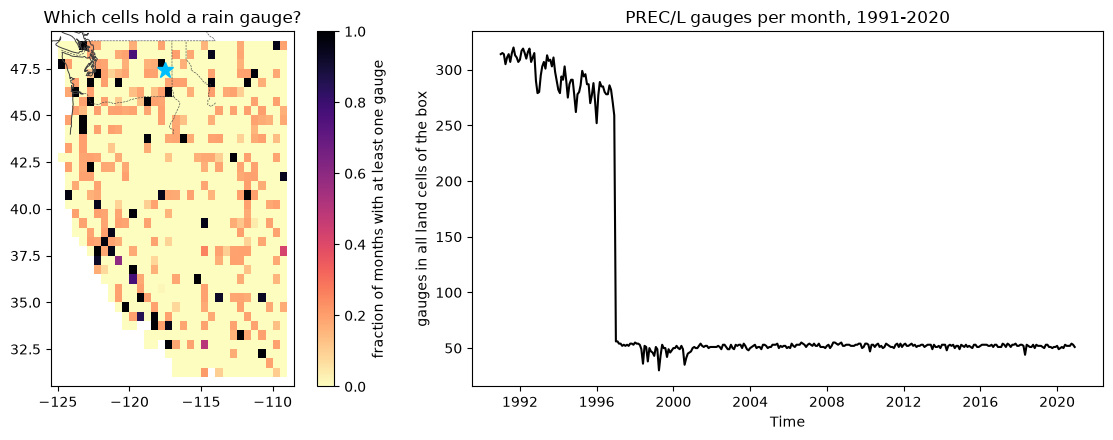

In [11]:
t = pd.read_csv(lab.TABLE_FILE)
print("gauges in the Spokane model cell, all 360 months:", sorted(t["n_gauges"].unique()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
frac = static["gauges_frac_months_with_gauge"].where(grid["soilw"].notnull().any("time"))
pc = axes[0].pcolormesh(grid["lon"] - 360, grid["lat"], frac, cmap="magma_r", vmin=0, vmax=1, shading="nearest")
fig.colorbar(pc, ax=axes[0], label="fraction of months with at least one gauge")
lab.draw_map(axes[0], places=False)
axes[0].plot(st_lon, st_lat, "*", color="deepskyblue", ms=12)
axes[0].set_xlim(-125.5, -108.5); axes[0].set_ylim(30.5, 49.5); axes[0].set_aspect(1 / np.cos(np.deg2rad(40)))
axes[0].set_xticks(range(-125, -108, 5))
axes[0].set_title("Which cells hold a rain gauge?")
static["gauges_total"].plot(ax=axes[1], color="k")
axes[1].set_ylabel("gauges in all land cells of the box"); axes[1].set_title("PREC/L gauges per month, 1991-2020")
plt.tight_layout(); plt.show()

**Q1.3** The north-south and east-west size of the Spokane cell in km (one degree of latitude is about 111.2 km); the mean number of gauges per month in the box's land cells in 1991-1996 and in 1997-2020 (`static["gauges_total"]`); is this file raw or derived?

In [12]:
q1_cell_km = None          # (north-south km, east-west km)
q1_gauges = None           # (mean gauges per month 1991-1996, mean gauges per month 1997-2020)
q1_raw_or_derived = None   # "raw" or "derived", with a few words on why
for qid, ans in [("q1_cell_km", q1_cell_km), ("q1_gauges", q1_gauges), ("q1_raw_or_derived", q1_raw_or_derived)]:
    print(qid, end=": "); chk.check(qid, ans)

q1_cell_km: not answered yet
q1_gauges: not answered yet
q1_raw_or_derived: not answered yet


In [13]:
# Worked solution, open after you tried
c_lat = float(t["cell_lat"].iloc[0])
ns, ew = 111.2 * 0.5, 111.2 * 0.5 * np.cos(np.deg2rad(c_lat))
g = static["gauges_total"].to_series()
early, late = g[g.index.year <= 1996].mean(), g[g.index.year >= 1997].mean()
print(f"cell at {c_lat} N: {ns:.1f} km north-south, {ew:.1f} km east-west, about {ns * ew:.0f} km2")
print(f"gauges per month in the box: {early:.0f} (1991-1996), {late:.0f} (1997-2020)")
for qid, ans in [("q1_cell_km", (ns, ew)), ("q1_gauges", (early, late)),
                 ("q1_raw_or_derived", "derived: model output from interpolated gauge and thermometer analyses")]:
    print(qid, end=": "); chk.check_worked(qid, ans)
# The Spokane cell never holds a gauge: its precipitation is interpolated from neighbouring cells.
# The gauge count in the box drops about sixfold after 1996: PREC/L mixes a large historical archive with a
# smaller set of stations that report in near real time. CPC's page lists "dealing with inhomogeneity resulting
# from changes in number of gauges over time" as still to come. Any trend across 1997 inherits the change.

cell at 47.25 N: 55.6 km north-south, 37.7 km east-west, about 2098 km2
gauges per month in the box: 295 (1991-1996), 51 (1997-2020)
q1_cell_km: correct
q1_gauges: correct
q1_raw_or_derived: correct


```{admonition} If you are stuck
:class: hint
- `job.status()` says the download stopped (timeout, connection error): the server is busy. Continue; after class, run `job = lab.start_download(mine)` again.
- Fingerprints differ but sizes and counts agree: compare the values (worked solution of Q1.1). Different numbers mean a revision or damage; same numbers, different bytes, a different writer.
```

## Part 2. The table: one model cell near Spokane (about 8 min)

**What to do:** read the table, physical limits, one real extreme and one error.

One row per month at the cell nearest USCRN Spokane 17 SSW (Turnbull National Wildlife Refuge).

In [14]:
t = pd.read_csv(lab.TABLE_FILE)
print(t.dtypes); display(t.head(3)); display(t.tail(3))
print("units from the provider's attributes:", {v: grid[v].attrs.get("units") for v in ("soilw", "precip")})
print("long names:", {v: grid[v].attrs.get("long_name") for v in ("soilw", "precip")})

month                         str
cell_lat                  float64
cell_lon_east             float64
soilw_mm                  float64
precip_mm_per_day         float64
n_gauges                    int64
air_temp_degK             float64
soilw_ltm_1991_2020_mm    float64
dtype: object


,month,cell_lat,cell_lon_east,soilw_mm,precip_mm_per_day,n_gauges,air_temp_degK,soilw_ltm_1991_2020_mm
0,1991-01,47.25,242.25,212.047,1.1687,0,270.69,239.802
1,1991-02,47.25,242.25,219.111,0.6818,0,278.28,258.646
2,1991-03,47.25,242.25,233.968,1.7001,0,276.69,270.113


,month,cell_lat,cell_lon_east,soilw_mm,precip_mm_per_day,n_gauges,air_temp_degK,soilw_ltm_1991_2020_mm
357,2020-10,47.25,242.25,151.094,1.2935,0,282.873,143.993
358,2020-11,47.25,242.25,178.971,1.8523,0,276.983,170.308
359,2020-12,47.25,242.25,223.269,1.5667,0,273.842,207.601


units from the provider's attributes: {'soilw': 'mm', 'precip': 'mm/day'}
long names: {'soilw': 'Model-Calculated Monthly Mean Soil Moisture', 'precip': 'Average Monthly Rate of Precipitation'}


A row is one month over about 56 by 38 km. Units are in the NetCDF (Network Common Data Form) attributes printed above. In the provider's files, cells that are not model land hold -9.96921e+36, which xarray reads as NaN.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Q2.1** Before looking, write the physical limits for soil water (mm) and for a monthly mean precipitation rate (mm/day), from the model (Part 0) and the climate, not from this cell.

In [15]:
q2_limits = None   # {"soilw_mm": (low, high), "precip_mm_per_day": (low, high)}
chk.check("q2_limits", q2_limits)

not answered yet


In [16]:
# Worked solution, open after you tried
sol_limits = {"soilw_mm": (0.0, 760.0), "precip_mm_per_day": (0.0, 60.0)}
for col, var, (lo, hi) in [("soilw_mm", "soilw", sol_limits["soilw_mm"]),
                           ("precip_mm_per_day", "precip", sol_limits["precip_mm_per_day"])]:
    box = grid[var]
    print(f"{col}: Spokane cell {t[col].min():.3f} to {t[col].max():.3f}; whole box {float(box.min()):.3f} to "
          f"{float(box.max()):.3f}; values outside [{lo}, {hi}] in the box: {int(((box < lo) | (box > hi)).sum())}")
chk.check_worked("q2_limits", sol_limits)
# The bucket holds between nothing and its 760 mm capacity. Precipitation cannot be negative. Its upper limit
# is not sharp: a month cannot average more than its wettest day (656 mm in 24 hours, California, January 1943,
# NCEI State Climate Extremes Committee). 60 mm/day is about twice this box's wettest month and keeps every real one.

soilw_mm: Spokane cell 102.406 to 398.034; whole box 0.000 to 741.667; values outside [0.0, 760.0] in the box: 0
precip_mm_per_day: Spokane cell 0.011 to 3.803; whole box 0.000 to 27.820; values outside [0.0, 60.0] in the box: 0
correct: your limits bracket every value and follow the physics


**Q2.2 One real extreme.** Find the month with the least soil water at this cell. Real or error? Look at the precipitation before it.

**Q2.3 One error.** The USCRN station's readme (`snapshots/uscrn_daily01_readme.txt`, note C) says how missing values are written. Which number stands for a missing soil moisture value? The next cell shows its effect on a monthly mean.

In [17]:
u_raw = lab.read_uscrn()
sm5 = u_raw.loc["2015":"2020", "SOIL_MOISTURE_5_DAILY"]
print("smallest values in the 5 cm column as served:", np.sort(sm5.unique())[:3])
print("January 2017 mean, codes left in:", round(sm5.loc["2017-01"].mean(), 3), "m3/m3")
print("January 2017 mean, codes removed:", sm5.loc["2017-01"].where(sm5.loc["2017-01"] > -99).mean(), "m3/m3")

q2_extreme = None     # ("YYYY-MM", "real" or "error")
q2_sentinel = None    # the missing-value code for USCRN soil moisture
print("Q2.2:", end=" "); chk.check("q2_extreme", q2_extreme)
print("Q2.3:", end=" "); chk.check("q2_sentinel", q2_sentinel)

smallest values in the 5 cm column as served: [-9.9e+01  1.1e-02  1.2e-02]
January 2017 mean, codes left in: -99.0 m3/m3
January 2017 mean, codes removed: nan m3/m3
Q2.2: not answered yet
Q2.3: not answered yet


In [18]:
# Worked solution, open after you tried
i = t["soilw_mm"].idxmin()
print(t.loc[i - 4:i + 1, ["month", "soilw_mm", "precip_mm_per_day", "air_temp_degK"]])
print("Q2.2:", end=" "); chk.check_worked("q2_extreme", (t.loc[i, "month"], "real"))
print("Q2.3:", end=" "); chk.check_worked("q2_sentinel", -99.0)
# The driest month follows a dry summer, sits inside 0-760 mm and recovers with autumn rain: a real extreme
# that cleaning must keep. -99.000 is an error only if read as a measurement: it drags a monthly mean far below
# zero. January 2017 has no valid 5 cm value at all (frozen soil, Part 3), so its mean without the codes is NaN.

       month  soilw_mm  precip_mm_per_day  air_temp_degK
137  2002-06   198.773             1.1890         289.84
138  2002-07   158.870             0.1687         294.44
139  2002-08   131.399             0.9128         291.75
140  2002-09   113.104             0.4180         288.22
141  2002-10   102.406             0.3029         280.12
142  2002-11   108.777             1.5995         276.79
Q2.2: correct
Q2.3: correct


```{admonition} If you are stuck
:class: hint
- Air temperatures near 280: the column is in kelvin (subtract 273.15).
- The check rejects your limits: they must hold for any cell, not only at Spokane.
```

## Part 3. A 1D array: the time series at the Spokane cell (about 8 min)

**What to do:** sampling interval and gaps, the series, a real sensor problem in the station's record.

One value per calendar month and no gaps, but months differ in length: a monthly mean rate times the days gives the total. The bucket's memory smooths the noise of precipitation.

steps between records (days): [np.int64(28), np.int64(29), np.int64(30), np.int64(31)]


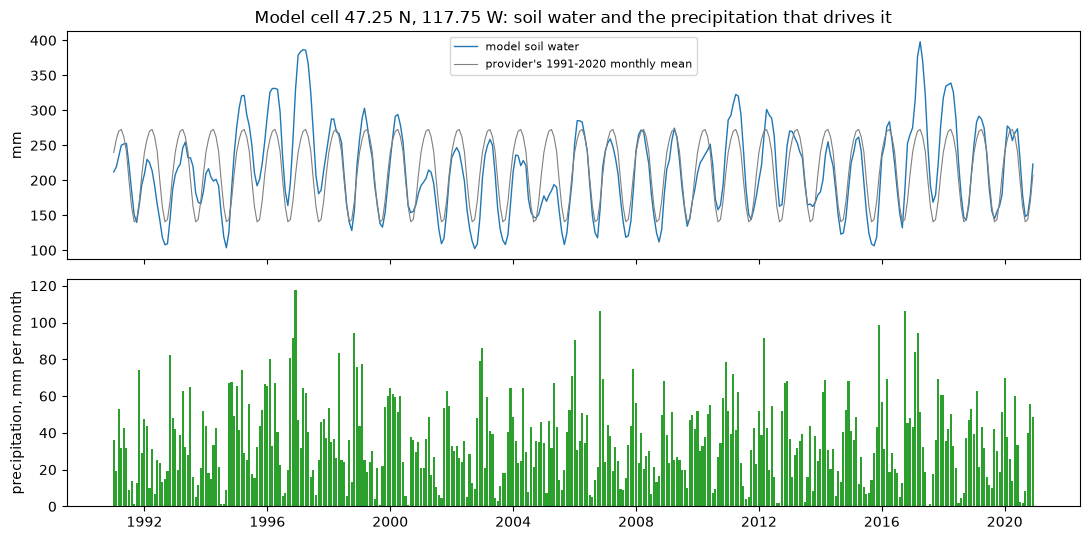

not answered yet


In [19]:
dates = pd.to_datetime(t["month"])
steps = np.diff(dates.values).astype("timedelta64[D]").astype(int)
print("steps between records (days):", sorted(set(steps)))

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(dates, t["soilw_mm"], color="tab:blue", lw=1, label="model soil water")
ax[0].plot(dates, t["soilw_ltm_1991_2020_mm"], color="0.5", lw=0.8, label="provider's 1991-2020 monthly mean")
ax[0].set_ylabel("mm"); ax[0].legend(fontsize=8)
ax[1].bar(dates, t["precip_mm_per_day"] * dates.dt.days_in_month, width=25, color="tab:green")
ax[1].set_ylabel("precipitation, mm per month")
ax[0].set_title(f"Model cell {t['cell_lat'][0]} N, {360 - t['cell_lon_east'][0]} W: soil water and the precipitation that drives it")
plt.tight_layout(); plt.show()

q3_interval = None     # (shortest, longest) step between records in days
chk.check("q3_interval", q3_interval)

In [20]:
# Worked solution, open after you tried
chk.check_worked("q3_interval", (int(min(steps)), int(max(steps))))
# 28 to 31 days. A "monthly" series is not evenly sampled; a spectrum or fit that assumes equal steps carries
# a small error, and monthly totals need the number of days.

correct


**A real sensor problem: frozen soil.** The station's Stevens Hydra Probe II sensors (5, 10, 20, 50 and 100 cm, three sets) measure the soil's dielectric permittivity at 50 MHz and convert it to volumetric water content ([National Centers for Environmental Information, NCEI](https://www.ncei.noaa.gov/pub/data/uscrn/documentation/site/sensors/soil/Descriptions/Soil_StevensHydra-SDI-12.pdf)). Liquid water has a permittivity near 80 and ice near 3, so frozen soil looks almost dry. The daily value averages the hourly values of the three probes (readme, note J). Look at the winters.

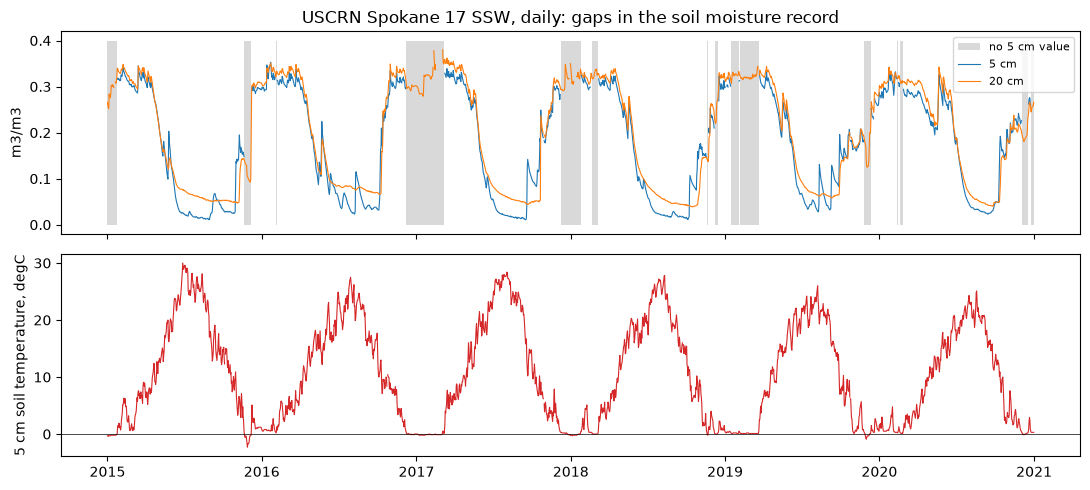

In [21]:
u = lab.uscrn_daily().loc["2015":"2020"]
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].fill_between(u.index, 0, 0.4, where=u["SOIL_MOISTURE_5_DAILY"].isna(), color="0.85", lw=0, label="no 5 cm value")
ax[0].plot(u.index, u["SOIL_MOISTURE_5_DAILY"], lw=0.8, label="5 cm")
ax[0].plot(u.index, u["SOIL_MOISTURE_20_DAILY"], lw=0.8, label="20 cm")
ax[0].set_ylabel("m3/m3"); ax[0].legend(fontsize=8)
ax[1].plot(u.index, u["SOIL_TEMP_5_DAILY"], color="tab:red", lw=0.8)
ax[1].axhline(0, color="k", lw=0.5); ax[1].set_ylabel("5 cm soil temperature, degC")
ax[0].set_title("USCRN Spokane 17 SSW, daily: gaps in the soil moisture record")
plt.tight_layout(); plt.show()

**Q3.2** What percent of days in December to February (2015-2020) have no 5 cm soil moisture value, and what percent in June to August?

In [22]:
q3_frozen = None      # (percent missing in Dec-Feb, percent missing in Jun-Aug)
chk.check("q3_frozen", q3_frozen)

not answered yet


In [23]:
# Worked solution, open after you tried
miss = u["SOIL_MOISTURE_5_DAILY"].isna()
m = u.index.month
winter, summer = 100 * miss[np.isin(m, [12, 1, 2])].mean(), 100 * miss[np.isin(m, [6, 7, 8])].mean()
print(f"missing 5 cm days: {winter:.1f} % in Dec-Feb, {summer:.1f} % in Jun-Aug")
print("median 5 cm soil temperature on missing days:", u.loc[miss, "SOIL_TEMP_5_DAILY"].median(), "degC;",
      "on other days:", u.loc[~miss, "SOIL_TEMP_5_DAILY"].median(), "degC")
chk.check_worked("q3_frozen", (winter, summer))
frozen = u["SOIL_TEMP_5_DAILY"] <= 0
print(f"days with 5 cm soil at or below 0 degC: {int(frozen.sum())}, of which without a 5 cm value: {int(miss[frozen].sum())}")
# Every day with a 5 cm soil temperature at or below 0 degC lacks a 5 cm value, and the gaps thin out with depth.
# The readme (note E) says values are reported missing when the raw data are flagged as erroneous; frozen
# readings are the likely reason. A monthly mean from the remaining days leans toward warm, unfrozen days;
# lab.uscrn_monthly_storage() keeps a month only with at least 20 complete days, so most winters drop out.

missing 5 cm days: 51.8 % in Dec-Feb, 0.0 % in Jun-Aug
median 5 cm soil temperature on missing days: 0.0 degC; on other days: 12.2 degC


correct
days with 5 cm soil at or below 0 degC: 191, of which without a 5 cm value: 191


```{admonition} If you are stuck
:class: hint
- `KeyError` on a column: print `u.columns` and copy the name exactly.
- The bar plot looks empty: precipitation is a rate (mm/day); the cell multiplies by the days in each month.
```

## Part 4. A 2D array: the grid (about 8 min, if you have time)

**What to do:** axes and their order, the climatology and its seasonal range, a cell that cannot be right.

The grid is a 3D array (time, latitude, longitude); a map of one month is a 2D array.

In [24]:
print(grid)
print("first latitudes:", grid["lat"].values[:3], "| first longitudes:", grid["lon"].values[:3])
print("spacing:", float(np.diff(grid["lat"]).mean()), "degree in latitude,", float(np.diff(grid["lon"]).mean()), "in longitude")

<xarray.Dataset> Size: 3MB
Dimensions:  (time: 360, lat: 36, lon: 32)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1991-01-01 1991-02-01 ... 2020-12-01
  * lat      (lat) float32 144B 48.75 48.25 47.75 47.25 ... 32.25 31.75 31.25
  * lon      (lon) float32 128B 235.2 235.8 236.2 236.8 ... 249.8 250.2 250.8
Data variables:
    soilw    (time, lat, lon) float32 2MB 596.5 655.6 666.0 ... 116.6 101.1
    precip   (time, lat, lon) float32 2MB 7.939 6.54 4.804 ... 0.255 0.2587
Attributes:
    title:              CPC soil moisture (V2) and PREC/L precipitation, mont...
    source:             NOAA PSL, https://psl.noaa.gov/data/gridded/data.cpcs...
    subset_written_by:  lab_s07_lsm_synthetic.write_grid
first latitudes: [48.75 48.25 47.75] | first longitudes: [235.25 235.75 236.25]
spacing: -0.5 degree in latitude, 0.5 in longitude


**Q4.1** Is latitude stored from south to north ("ascending") or north to south ("descending")? Give the file's coordinates (lat, lon in its own convention) of the cell nearest the Spokane station (47.41 N, 117.52 W).

In [25]:
q4_lat_order = None    # "ascending" or "descending"
q4_cell = None         # (lat, lon) as stored in the file
print("Q4.1 order:", end=" "); chk.check("q4_lat_order", q4_lat_order)
print("Q4.1 cell:", end=" "); chk.check("q4_cell", q4_cell)

Q4.1 order: not answered yet
Q4.1 cell: not answered yet


In [26]:
# Worked solution, open after you tried
cell = grid["soilw"].sel(lat=st_lat, lon=st_lon % 360, method="nearest")
print("descending" if grid["lat"][0] > grid["lat"][-1] else "ascending", float(cell.lat), float(cell.lon))
print("Q4.1 order:", end=" "); chk.check_worked("q4_lat_order", "descending")
print("Q4.1 cell:", end=" "); chk.check_worked("q4_cell", (float(cell.lat), float(cell.lon)))
# With descending latitude, grid.sel(lat=slice(31, 49)) is empty: the slice must run from 49 to 31.
# Longitude runs from 0 to 360 degrees east: 117.52 W is 242.48 E, nearest cell 242.25.

descending 47.25 242.25
Q4.1 order: correct
Q4.1 cell: correct


largest difference between our 1991-2020 climatology and the provider's (mm): 0.0


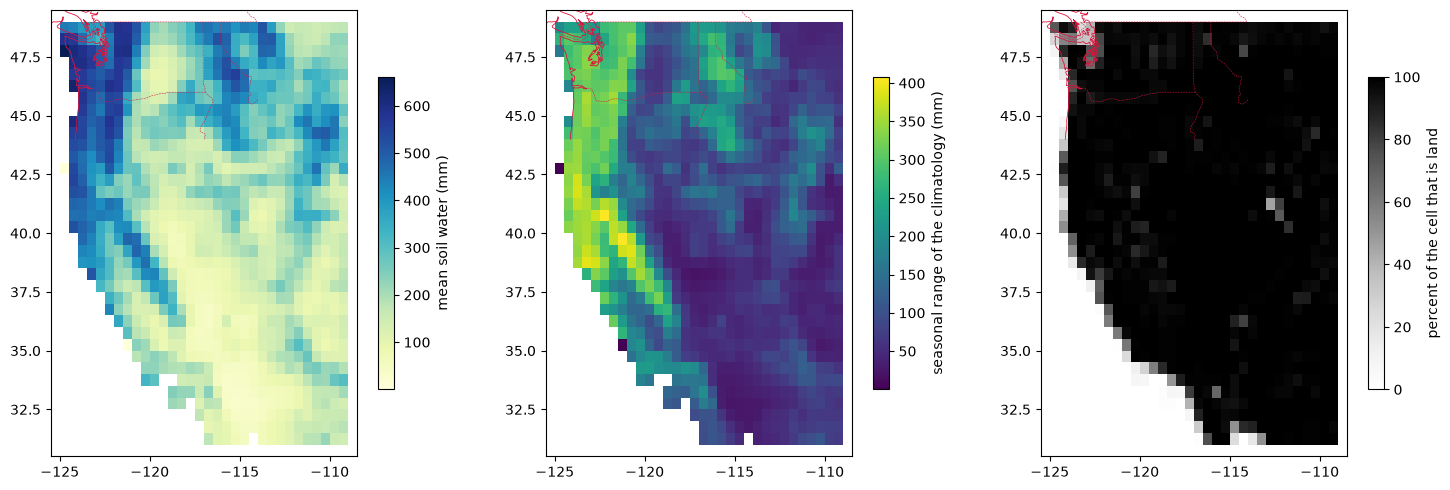

In [27]:
clim = grid["soilw"].groupby("time.month").mean()
print("largest difference between our 1991-2020 climatology and the provider's (mm):",
      float(np.nanmax(np.abs(clim.values - static["soilw_ltm"].values))))
srange = clim.max("month") - clim.min("month")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (field, label, cmap) in zip(axes, [(clim.mean("month"), "mean soil water (mm)", "YlGnBu"),
                                          (srange, "seasonal range of the climatology (mm)", "viridis"),
                                          (static["landperc"], "percent of the cell that is land", "Greys")]):
    pc = ax.pcolormesh(grid["lon"] - 360, grid["lat"], field, cmap=cmap, shading="nearest")
    fig.colorbar(pc, ax=ax, shrink=0.7, label=label)
    lab.draw_map(ax, color="crimson", lw=0.6, places=False)
    ax.set_xlim(-125.5, -108.5); ax.set_ylim(30.5, 49.5); ax.set_aspect(1 / np.cos(np.deg2rad(40)))
    ax.set_xticks(range(-125, -108, 5))
plt.tight_layout(); plt.show()

**Q4.2** Where is the seasonal range largest?
A. the Pacific slope from northern California to Washington, west of the Sierra Nevada and the Cascades;
B. the Great Basin of Nevada and Utah;
C. the deserts of Arizona and southeastern California;
D. about the same everywhere.

**Q4.3** Find a land cell whose soil water never exceeds 1 mm in 30 years, look at its precipitation and land percent, and give its (lat, lon).

In [28]:
q4_region = None      # "A", "B", "C" or "D"
q4_bad_cell = None    # (lat, lon)
print("Q4.2:", end=" "); chk.check("q4_region", q4_region)
print("Q4.3:", end=" "); chk.check("q4_bad_cell", q4_bad_cell)

Q4.2: not answered yet
Q4.3: not answered yet


In [29]:
# Worked solution, open after you tried
print("Q4.2:", end=" "); chk.check_worked("q4_region", "A")
smax = grid["soilw"].max("time").to_series()
bad = smax[smax < 1.0]
for (la, lo), v in bad.items():
    print(f"{la} N, {360 - lo} W: max soil water {v:.3f} mm, mean precipitation "
          f"{float(grid['precip'].sel(lat=la, lon=lo).mean()):.2f} mm/day, land {float(static['landperc'].sel(lat=la, lon=lo)):.0f} %, "
          f"missing months {int(grid['soilw'].sel(lat=la, lon=lo).isnull().sum())}")
print("Q4.3:", end=" "); chk.check_worked("q4_bad_cell", bad.index[0])
# Mediterranean climate: winter storms fill the bucket and summers are rainless, so the range is largest on the
# Pacific slope; in the deserts and the Great Basin the bucket stays low all year.
# The two cells are coastal, 1 or 2 % land. They get several mm/day of rain, yet the model keeps them empty,
# and from January 2014 on they are missing. PSL's description says: "There is no missing data though the ocean
# has 0's ... Grids where the percent of land is zero are 'missing'." These cells keep the model's ocean zeros,
# while PREC/L, with a different land mask, gives them coastal rain. Drop them (land percent below 50 is a
# defensible rule) before any statistic over land. Part 5 plants the same "ocean = 0" problem.

Q4.2: correct
42.75 N, 124.75 W: max soil water 0.090 mm, mean precipitation 4.34 mm/day, land 2 %, missing months 84
35.25 N, 121.25 W: max soil water 0.062 mm, mean precipitation 1.33 mm/day, land 1 %, missing months 84
Q4.3: correct


```{admonition} If you are stuck
:class: hint
- `grid.sel(lat=slice(31, 49))` returns nothing: latitude runs north to south, use `slice(49, 31)`.
- Negative longitudes make `sel` fail: the file uses 0 to 360 degrees east; add 360.
```

## Part 5. A synthetic twin with planted problems (about 15 min)

**What to do:** build your twin; (a) list what could go wrong; (b) hunt and record findings; (c) drought frequency three ways; (d) reflect.

The twin has the structure of the real Pacific Northwest grid and a known truth: our own small leaky bucket (not CPC's code: snow below +2 degC, Thornthwaite (1948) evaporation) run on synthetic weather around each cell's 1991-2020 climatology, with a dry spell in early 2015, a warm anomaly that year and a warming of 0.02 degC per year. Five problems typical of land-surface products are planted in the forcing, the model run or the file writing; your NetID picks which five of ten kinds, and where.

In [30]:
twin = lab.make_twin(NETID)
print(twin)
print(lab.TWIN_README)
df = lab.read_twin(twin.path)
print(f"\nyour file: {lab.where(twin.path)} ({twin.path.stat().st_size / 1e6:.1f} MB, {len(df)} rows)")
display(df.head())

Twin(netid='', file=lsm_twin_class.csv, 5 planted problems, 14 x 20 cells, 360 months)
Synthetic twin of the CPC soil moisture grid, Pacific Northwest, monthly, January 1991 to December 2020.
Columns: time (first day of the month), lat (degrees north, cell centre), lon (degrees east from 0 to 360,
cell centre), soil_moisture_mm (monthly mean water in a one-layer 1.6 m soil column, holding capacity 760 mm),
precip_mm_per_day (monthly mean precipitation rate from a gauge analysis over land only).
Grid: 0.5 degree. Rows exist where at least one of the two variables has a value.

your file: (temporary folder of the book build)/lsm_twin_class.csv (4.4 MB, 99000 rows)


,time,lat,lon,soil_moisture_mm,precip_mm_per_day
0,1991-01-01,48.75,235.25,124.3410,5.8113
1,1991-01-01,48.75,235.75,149.4778,7.2812
2,1991-01-01,48.75,236.25,86.1407,3.6139
3,1991-01-01,48.75,236.75,79.0594,3.2198
4,1991-01-01,48.75,237.25,98.1671,4.3168


```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**(a) Before you look.** List at least three things that could go wrong in a monthly soil-water product: gauges, gridded analysis, model run, file writing.

In [31]:
q5a = []     # for example: "a gauge reports in inches instead of mm", ...
chk.check("q5a", q5a)

not answered yet


**(b) Hunt.** From the summary and one cell below, follow your list: the limits of Q2.1, rows per month, coordinates, the seasonal cycle of each cell, whether soil water answers precipitation in time and place. Record each problem as a finding (variable, first and last month, lat and lon range or `None`, what is wrong, why it is implausible). A finding counts when variable, months and cells overlap a planted problem; for a whole-record problem, "what" and "why" must name the mechanism. Wet coast, dry inland, the 2015 dry spell and the wettest coastal winters are real structure.

,time,lat,lon,soil_moisture_mm,precip_mm_per_day
count,99000,99000.000,99000.000,99000.000,96120.000
mean,2005-12-15 22:56:00,45.541,-13.914,416.326,2.059
min,1991-01-01 00:00:00,42.250,-124.750,0.000,0.044
25%,1998-06-23 12:00:00,43.750,-121.250,292.765,0.684
50%,2005-12-16 12:00:00,45.750,-117.750,407.293,1.275
75%,2013-06-08 12:00:00,47.250,236.750,530.534,2.503
max,2020-12-01 00:00:00,48.750,244.750,760.000,37.700
std,NaN,2.008,164.111,157.014,2.275


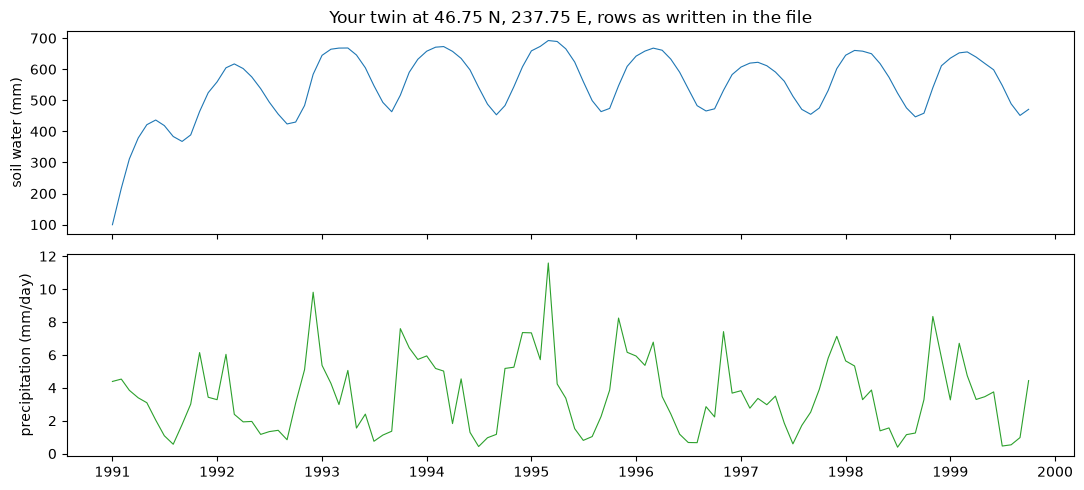

In [32]:
d = df.copy()
d["time"] = pd.to_datetime(d["time"])
display(d.describe().round(3))

one = d[(d["lat"] == 46.75) & (d["lon"] == 237.75)]       # one land cell in southwestern Washington, as written
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(one["time"], one["soil_moisture_mm"], lw=0.8)
ax[0].set_ylabel("soil water (mm)")
ax[1].plot(one["time"], one["precip_mm_per_day"], lw=0.8, color="tab:green")
ax[1].set_ylabel("precipitation (mm/day)")
ax[0].set_title("Your twin at 46.75 N, 237.75 E, rows as written in the file")
plt.tight_layout(); plt.show()

In [33]:
findings = [
    # dict(variable="soil", start="YYYY-MM", end="YYYY-MM", lat=None, lon=None,
    #      what="...", why="..."),
]
chk.score_findings(findings, twin)

not answered yet


In [34]:
chk.score_findings(findings, twin, reveal=True)    # when you have recorded what you can: which kinds you missed, not where

not answered yet


**(c) Drought frequency, three ways.** The percent of cell-months in 2011-2020 below the 20th percentile of the same cell and calendar month in 1991-2010 (20 % of baseline months by construction). Its true value depends on your twin's weather. Cleaning can move it away from the truth: removing months shortens the baseline, and a forcing error stays in the soil water. Write `my_clean`, one line per finding.

In [35]:
def my_clean(df):
    out = df.copy()
    # one line per finding, each with its reason; two examples, to use only if you found these problems:
    # out["lon"] = out["lon"] % 360                          # one longitude convention for the whole file
    # out = out.drop_duplicates(["time", "lat", "lon"])      # a month written twice
    return out

D_truth = lab.drought_frequency(twin.truth)
D_file = lab.drought_frequency(df)
D_clean = lab.drought_frequency(my_clean(df))
chk.check("q5c", (D_truth, D_file, D_clean))

drought months 2011-2020: truth 17.2 %, file as received 8.1 %, after your cleaning 8.1 %
my_clean: not answered yet (your cleaning has not changed the drought frequency)


```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**(d) Reflect.** For each problem you found, did it push the drought frequency up or down, and why? Which could cleaning not undo? Which leave it untouched but would harm another use of the file?

In [36]:
q5d = ""     # a few sentences
chk.check("q5d", q5d)

not answered yet


In [37]:
# Worked solution, open after you tried
def hunt(df, verbose=True):
    """The worked solution's hunt: physical checks, a record of each finding, and a cleaned copy."""
    found = []
    say = print if verbose else (lambda *a, **k: None)
    d = df.copy()
    d["time"] = pd.to_datetime(d["time"])

    # 1. Longitude convention: negative longitudes appear part way through.
    neg = d["lon"] < 0
    if neg.any():
        t0, t1 = d.loc[neg, "time"].min(), d.loc[neg, "time"].max()
        found.append(dict(variable="both", start=f"{t0:%Y-%m}", end=f"{t1:%Y-%m}", lat=None, lon=None,
                          what="longitudes change from 0-360 to -180-180",
                          why="the same cell gets two names, so its record splits in two"))
        say(f"negative longitudes from {t0:%Y-%m}")
        d["lon"] = d["lon"] % 360

    # 2. Duplicated months: the same time, lat, lon twice.
    dup = d.duplicated(["time", "lat", "lon"], keep="first")
    for t in sorted(d.loc[dup, "time"].unique()):
        t = pd.Timestamp(t)
        found.append(dict(variable="both", start=f"{t:%Y-%m}", end=f"{t:%Y-%m}", lat=None, lon=None,
                          what="every row of this month appears twice",
                          why="one month cannot have two values per cell; it would count twice in any statistic"))
        say(f"duplicated month {t:%Y-%m}")
    d = d[~dup]

    g = d.set_index(["time", "lat", "lon"]).to_xarray()
    sm, pr = g["soil_moisture_mm"], g["precip_mm_per_day"]
    times = pd.DatetimeIndex(g["time"].values)

    # 3. Constant cells with soil water but no precipitation: ocean leaking in.
    const = (sm.std("time") == 0) & sm.notnull().all("time")
    if bool(const.any()):
        cells = const.to_series()[const.to_series()].index
        la = [c[0] for c in cells]
        lo = [c[1] for c in cells]
        found.append(dict(variable="soil", start="1991-01", end="2020-12", lat=(min(la), max(la)),
                          lon=(min(lo), max(lo)), what=f"{len(cells)} cells hold one constant value for 30 years",
                          why="real soil water rises and falls with the seasons; these cells have no precipitation, so they are ocean"))
        say(f"{len(cells)} constant cells, value {float(sm.where(const).max()):.1f}")
        sm = sm.where(~const)
    land = sm.notnull().sum("time") > 0.5 * len(times)

    # 4. Zero-filled months and months in metres, from the land-median of each month.
    med = sm.where(land).median(["lat", "lon"]).to_series()
    for t in med.index[med == 0]:
        found.append(dict(variable="soil", start=f"{t:%Y-%m}", end=f"{t:%Y-%m}", lat=None, lon=None,
                          what="soil water is exactly 0 everywhere", why="a bucket cannot empty and refill within a month; evaporation slows as it dries"))
        say(f"zero month {t:%Y-%m}")
        sm.loc[dict(time=t)] = np.nan
    small = med[(med > 0) & (med < 5)]
    if len(small):
        # metres (divide by 1000) or a volumetric fraction of the 1.6 m column (divide by 1600)?
        normal = med[(med >= 5) & (med.index.month.isin(small.index.month))]
        ratio = float(normal.groupby(normal.index.month).median().mean() / small.groupby(small.index.month).median().mean())
        factor = min((1000.0, 1600.0), key=lambda f_: abs(np.log(ratio / f_)))
        unit = "metres" if factor == 1000.0 else "a volumetric fraction (m3/m3 over 1600 mm)"
        found.append(dict(variable="soil", start=f"{small.index.min():%Y-%m}", end=f"{small.index.max():%Y-%m}",
                          lat=None, lon=None, what=f"values about {factor:.0f} times too small",
                          why=f"a 1.6 m column holding under 1 mm everywhere is impossible; these are {unit}"))
        say(f"{unit} from {small.index.min():%Y-%m} to {small.index.max():%Y-%m} (ratio to normal months {ratio:.0f})")
        sm.loc[dict(time=small.index)] = sm.sel(time=small.index) * factor

    # 5. Spin-up: the land mean at the start sits far from its own later climatology.
    lm = sm.where(land).mean(["lat", "lon"]).to_series()
    late = lm[lm.index.year >= 1996]
    clim = late.groupby(late.index.month).mean()
    an = lm - clim.reindex(lm.index.month).values
    s = an[an.index.year >= 1996].std()
    bad = (an.abs() > 2.5 * s).to_numpy()
    n0 = 0
    while n0 < len(bad) and (bad[n0] or bad[n0:n0 + 3].any()):
        n0 += 1
    if n0 > 0:
        # drop until the drift is smaller than the natural spread: the first month after which the
        # land-mean anomaly stays within 1.5 standard deviations for a whole year
        quiet = (an.abs() < 1.5 * s).to_numpy()
        n_drop = next(i for i in range(n0, len(quiet) - 12) if quiet[i:i + 12].all())
        found.append(dict(variable="soil", start="1991-01", end=f"{times[n_drop - 1]:%Y-%m}", lat=None, lon=None,
                          what=f"the first {n0} months sit far from the later climatology, then drift toward it",
                          why="the model was started from a soil water it had not reached by itself (spin-up)"))
        say(f"spin-up: first {n0} months obvious, drift settles after {n_drop} months: dropped")
        sm.loc[dict(time=times[:n_drop])] = np.nan

    # 6. Precipitation over cells the soil model calls ocean: grid offset.
    wet_ocean = (pr.notnull().any("time") & sm.isnull().all("time")).sum()
    if int(wet_ocean) > 0:
        found.append(dict(variable="precip", start="1991-01", end="2020-12", lat=None, lon=None,
                          what=f"precipitation on {int(wet_ocean)} cells where the soil model has ocean",
                          why="a land-only gauge analysis cannot report rain at sea; the grid is offset by one cell"))
        say(f"precip on {int(wet_ocean)} ocean cells: shifted one cell east to fix")
        pr = pr.shift(lon=1)

    # 7. Timing: does soil water respond to the rain before it falls?
    pm = pr.where(land).mean(["lat", "lon"]).to_series()
    dw = lm.diff()
    pa = pm - pm.groupby(pm.index.month).transform("mean")
    da = dw - dw.groupby(dw.index.month).transform("mean")
    r = {k: da.corr(pa.shift(k)) for k in (-1, 0, 1)}
    if r[-1] > r[0]:
        found.append(dict(variable="precip", start="1991-01", end="2020-12", lat=None, lon=None,
                          what="soil water changes correlate best with next month's precipitation",
                          why="the soil cannot respond to rain that has not fallen; the precipitation labels are one month late"))
        say(f"time shift: r(-1)={r[-1]:.2f} > r(0)={r[0]:.2f}")
        pr = pr.shift(time=-1)

    # 8. A single precipitation value far above anything else in that cell.
    ratio = pr.groupby("time.month") / pr.groupby("time.month").median("time")
    nb = pr.rolling(lat=3, lon=3, center=True, min_periods=4).sum() - pr.fillna(0)   # the eight neighbours
    n_nb = pr.notnull().rolling(lat=3, lon=3, center=True, min_periods=4).sum() - pr.notnull()
    vs_neighbours = pr / (nb / n_nb)
    spike = (ratio > 4.5) & (vs_neighbours > 4.0)          # far above its own usual AND above its neighbours
    if bool(spike.any()):
        sp = spike.to_series()[spike.to_series()].index
        for (t, la, lo) in sp:
            t = pd.Timestamp(t)
            found.append(dict(variable="both", start=f"{t:%Y-%m}", end=f"{t + pd.DateOffset(months=12):%Y-%m}",
                              lat=(la, la), lon=(lo, lo), what="one month of precipitation ten times the usual, and the soil stays full after it",
                              why="one cell's month is ten times its usual value while every neighbour is normal; in a real analysis a bad gauge would also smear into the cells around it"))
            say(f"precip spike {t:%Y-%m} at {la}, {lo}")
            pr.loc[dict(time=t, lat=la, lon=lo)] = np.nan
            sm.loc[dict(time=slice(t, t + pd.DateOffset(months=12)), lat=la, lon=lo)] = np.nan

    # 9. A step in precipitation east of the Cascades relative to the west.
    east = pr.where(land & (pr["lon"] > 239)).mean(["lat", "lon"]).to_series()
    west = pr.where(land & (pr["lon"] <= 239)).mean(["lat", "lon"]).to_series()
    ry = (east.groupby(east.index.year).sum() / west.groupby(west.index.year).sum())
    best, gap = None, 0
    for y in ry.index[3:-3]:
        g_ = ry[ry.index >= y].mean() / ry[ry.index < y].mean()
        if abs(np.log(g_)) > abs(np.log(gap)) if gap else True:
            best, gap = y, g_
    if gap and abs(np.log(gap)) > np.log(1.15):
        found.append(dict(variable="both", start=f"{best}-01", end="2020-12", lat=None, lon=(239.25, 244.75),
                          what=f"east-of-Cascades precipitation jumps by a factor {gap:.2f} relative to the west from {best}",
                          why="climate does not change by a third overnight; a change in the gauge network does"))
        say(f"step in east/west precipitation ratio in {best}: x{gap:.2f}")

    clean = sm.to_dataframe().reset_index()[["time", "lat", "lon", "soil_moisture_mm"]]
    clean["time"] = clean["time"].dt.strftime("%Y-%m-%d")
    return clean.dropna(), found


sol_clean, sol_findings = hunt(df)
lab.score_findings(sol_findings, twin, reveal=True, who="the worked solution")
Dt, Df, Dc = lab.drought_frequency(twin.truth), lab.drought_frequency(df), lab.drought_frequency(sol_clean)
print(f"drought months 2011-2020: truth {Dt:.1f} %, file {Df:.1f} %, worked cleaning {Dc:.1f} %; "
      f"the cleaning moved the number {'closer to' if abs(Dc - Dt) < abs(Df - Dt) else 'further from'} the truth")
# How each problem moves the drought frequency (D):
# - months in metres or in m3/m3, or filled with zeros: in 2011-2020 they count as drought (D up); in the
#   baseline they barely move a 20th percentile computed from 20 years.
# - constant ocean cells: never below their own percentile, so they add non-drought months (D down).
# - longitudes switching convention: each cell splits in two, and the part after the switch has a short
#   baseline or none; D is computed on fewer, different cells.
# - a duplicated month counts twice.
# - spin-up: the first years are too wet or too dry, which shifts the baseline percentiles. Dropping the
#   drift shortens the baseline; it does not restore it.
# - a gauge error or a gauge-network change entered the model: the soil water itself is wrong after it. No
#   cleaning of the soil file undoes that; you would fix the precipitation and rerun the model, or restrict D
#   to the unaffected region. Across 34 NetIDs, the worked cleaning ended further from the truth for 13: 7 carried
#   a gauge-network step, and the other 6 a spin-up whose removal shortened the baseline.
# - precipitation offset in time or in space leaves D unchanged, but ruins any correlation or machine-learning
#   model that uses precipitation as an input (Parts 6 and 7).

negative longitudes from 1999-11
8 constant cells, value 760.0
zero month 2017-06
spin-up: first 27 months obvious, drift settles after 28 months: dropped
step in east/west precipitation ratio in 2009: x1.31
The worked solution located 5 of the 5 planted problems.
Nothing missed.


drought months 2011-2020: truth 17.2 %, file 8.1 %, worked cleaning 8.4 %; the cleaning moved the number closer to the truth


```{admonition} If you are stuck
:class: hint
- `df.set_index(['time', 'lat', 'lon']).to_xarray()` fails with a non-unique index: that is a finding. Look at `df[df.duplicated(['time', 'lat', 'lon'], keep=False)]`.
- A map of the twin shows the region twice: some longitudes run from -180 to 180, some from 0 to 360. `df['lon'] % 360` gives one convention.
```

## Part 6. Correlations on the real data (about 8 min)

**What to do:** expected sign, correlations with lags, effective sample size, what the correlation means.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Q6.1** What sign do you expect for the correlation between this month's precipitation and soil water at the Spokane cell?

In [38]:
q6_sign = None    # +1 or -1
chk.check("q6_sign", q6_sign)

not answered yet


In [39]:
a = lab.spokane_anomalies()          # each value minus its 1991-2020 mean for that calendar month
rows = []
for name, x, y in [("raw series", t["soilw_mm"], t["precip_mm_per_day"]),
                   ("anomalies", a["soilw_mm"], a["precip_mm_per_day"])]:
    for k in range(4):
        yk = y.shift(k)                # precipitation k months earlier
        ok = x.notna() & yk.notna()
        rows.append((name, k, stats.pearsonr(x[ok], yk[ok])[0], stats.spearmanr(x[ok], yk[ok])[0]))
corr = pd.DataFrame(rows, columns=["series", "precip lead (months)", "Pearson", "Spearman"]).round(3)
display(corr)

,series,precip lead (months),Pearson,Spearman
0,raw series,0,0.315,0.330
1,raw series,1,0.605,0.629
2,raw series,2,0.656,0.679
3,raw series,3,0.565,0.561
4,anomalies,0,0.287,0.247
5,anomalies,1,0.473,0.410
6,anomalies,2,0.424,0.366
7,anomalies,3,0.358,0.312


**The traps.**
1. **A shared seasonal cycle.** Part of the raw correlation is "winter is wetter than summer". Anomalies remove the calendar-month means.
2. **Lag.** A wet month raises the soil water at the end of the month, and the monthly mean only partly. (In nature, snow would add a delay until melt; this model cannot.)
3. **Autocorrelation.** Soil water remembers last month; precipitation hardly does. The effective number of independent pairs is about $N_{\mathrm{eff}} = N\,(1 - r_x r_y)/(1 + r_x r_y)$, with $r_x$, $r_y$ the lag-one autocorrelations of the two anomaly series (Bretherton et al., 1999).
4. **A model driven by precipitation must correlate with it.**

**Q6.2** Which precipitation lead (0 to 3 months) gives the largest anomaly correlation? **Q6.3** $N_{\mathrm{eff}}$ for the anomaly correlation, and for two series that both have the soil's memory ($r_x$ twice). **Q6.4** The anomaly correlation measures: A. how strongly rain controls soil water in nature; B. that the model is wrong; C. how strongly the model turns its own precipitation input into soil water, a check of its equations, not independent evidence; D. nothing, because correlation is not causation.

In [40]:
q6_lag = None      # 0, 1, 2 or 3
q6_neff = None     # (N_eff soil vs precipitation, N_eff for two series with the soil's memory)
q6_meaning = None  # "A", "B", "C" or "D"
for qid, ans in [("q6_lag", q6_lag), ("q6_neff", q6_neff), ("q6_meaning", q6_meaning)]:
    print(qid, end=": "); chk.check(qid, ans)

q6_lag: not answered yet
q6_neff: not answered yet
q6_meaning: not answered yet


In [41]:
# Worked solution, open after you tried
chk.check_worked("q6_sign", 1)
an = corr[corr["series"] == "anomalies"].set_index("precip lead (months)")["Pearson"]
best = int(an.idxmax())
rx, ry = a["soilw_mm"].autocorr(1), a["precip_mm_per_day"].autocorr(1)
N = len(a)
neff = N * (1 - rx * ry) / (1 + rx * ry)
neff_mem = N * (1 - rx * rx) / (1 + rx * rx)
print(f"best lead {best} months; r1 soil {rx:.2f}, r1 precipitation {ry:.2f}; N = {N}, "
      f"N_eff = {neff:.0f}; with the soil's memory on both sides N_eff = {neff_mem:.0f}")
for qid, ans in [("q6_lag", best), ("q6_neff", (neff, neff_mem)), ("q6_meaning", "C")]:
    print(qid, end=": "); chk.check_worked(qid, ans)
# The raw series peak at a 2-month lead (about 0.66) for another reason: the seasonal cycle of soil water lags
# that of precipitation by a few months (Part 0), so a shift lines up two annual cycles. The anomalies show the
# month-to-month response, best at a 1-month lead because a monthly mean of storage only partly contains this
# month's rain (with no snowpack in the model, snow is not the reason).

correct
best lead 1 months; r1 soil 0.94, r1 precipitation 0.12; N = 360, N_eff = 288; with the soil's memory on both sides N_eff = 24
q6_lag: correct
q6_neff: correct
q6_meaning: correct


**The only independent evidence in this track** is the station's own probes. Three limits: the probes reach 100 cm and the model column 160 cm; a few square metres stand for a cell of about 2100 km² (Q1.3); and a station month needs 20 complete days, so frozen winters drop out (Part 3) and mostly warm-season months remain, where the missing snowpack matters least.

model against station: 59 months, r = 0.72; months in Dec-Feb: 6, in Jun-Aug: 18


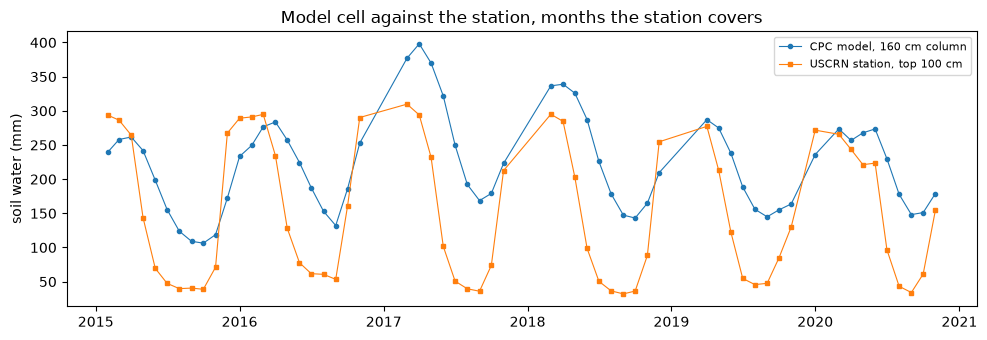

In [42]:
ins = lab.uscrn_monthly_storage()          # station soil water in the top 100 cm (mm), months with >= 20 complete days
both = t.set_index("month").join(ins, how="inner").dropna(subset=["insitu_top100cm_mm"])
r_in = stats.pearsonr(both["soilw_mm"], both["insitu_top100cm_mm"])[0]
season = pd.to_datetime(both.index).month
print(f"model against station: {len(both)} months, r = {r_in:.2f}; months in Dec-Feb: {int(np.isin(season, [12, 1, 2]).sum())}, "
      f"in Jun-Aug: {int(np.isin(season, [6, 7, 8]).sum())}")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(pd.to_datetime(both.index), both["soilw_mm"], "o-", ms=3, lw=0.8, label="CPC model, 160 cm column")
ax.plot(pd.to_datetime(both.index), both["insitu_top100cm_mm"], "s-", ms=3, lw=0.8, label="USCRN station, top 100 cm")
ax.set_ylabel("soil water (mm)"); ax.legend(fontsize=8)
ax.set_title("Model cell against the station, months the station covers")
plt.tight_layout(); plt.show()
# Both series carry the seasonal cycle and long memory, so r rests on far fewer independent samples than months;
# a fair test uses anomalies and N_eff, and needs more years than USCRN has here.

```{admonition} If you are stuck
:class: hint
- A correlation comes out NaN: one series has missing values; keep rows where both are present (`ok` above).
- Which way does `shift` go? `y.shift(1)` puts last month's precipitation on this month's row: precipitation leads by one month.
```

## Part 7. From data to a learning problem (about 10 min)

**What to do:** your chain of steps in order, the task and the target's distribution, split and balance.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Q7.1** Write, in order and each with its reason, the steps from the raw provider files to a table a model could learn from: selection of cells and months; what you remove, flag, or keep as a real extreme; aggregation; anomalies; a split by time or space that does not leak; balancing.

In [43]:
q7_pipeline = []   # ordered list of short strings, for example "1. select land cells with landperc >= 50: ..."
chk.check("q7_pipeline", q7_pipeline)

not answered yet


In [44]:
# Worked solution, open after you tried
sol_pipeline = [
    "1. download the provider files, check each is complete, cut the box, record fingerprint, size, counts, first and last month",
    "2. select cells with land percent >= 50 and drop cells whose soil water never exceeds 1 mm (ocean leaking in)",
    "3. select 1991-2020; flag months before and after the 1997 drop in gauges; keep every value inside 0-760 mm, "
    "including the driest months, which are real extremes",
    "4. convert units (precipitation rate to monthly totals with days per month; air temperature to degC)",
    "5. build features: precipitation of this month and the three before, temperature, calendar month, cell position",
    "6. split by time (train 1991-2010, test 2011-2020) and by space (whole blocks of cells held out)",
    "7. compute anomalies and drought thresholds from the training period only",
    "8. label drought months in train and test with the training thresholds",
    "9. balance on the training set only: class weights or resampling for drought months; weights by target bin for regression",
    "10. evaluate on the untouched test set: recall and precision-recall for drought months; errors per quantile for regression",
]
chk.check_worked("q7_pipeline", sol_pipeline)

correct order on three points (a split exists; anomalies, thresholds and balancing come after it). Compare the rest with the worked solution


**The task.** *Regression*: emulate the model, predicting soil water (or its anomaly) from precipitation and temperature. *Classification*: predict drought months (below the 1991-2010 20th percentile of the cell and calendar month), a minority class. The labels on the real grid:

drought months: 20.0 % in 1991-2010, 24.2 % in 2011-2020 (cells with >= 50 % land)


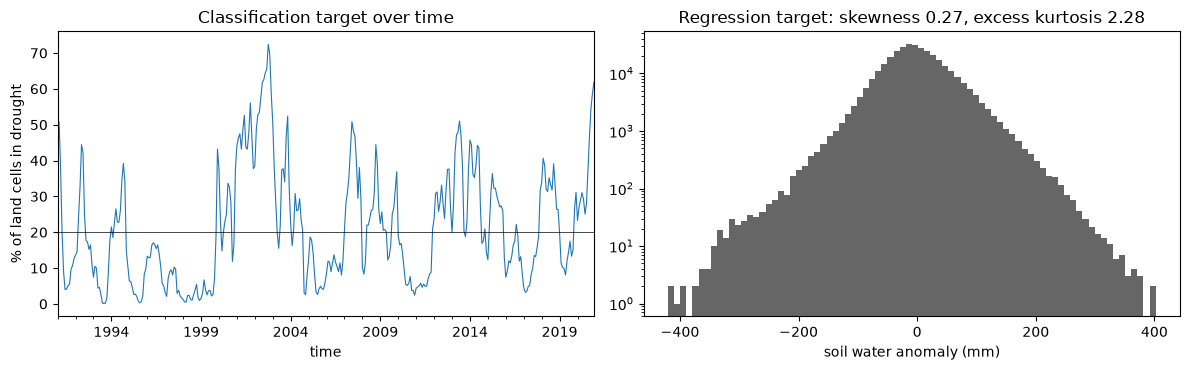

anomalies beyond -100 mm: 3.2 %, beyond +100 mm: 4.4 % of land cell-months


In [45]:
labels, p20 = lab.real_drought_labels()
cells_ok = (static["landperc"] >= 50) & (grid["soilw"].max("time") >= 1)
y = labels.where(cells_ok)
rate = y.mean(["lat", "lon"]).to_series() * 100
print(f"drought months: {float(y.sel(time=slice('1991', '2010')).mean()) * 100:.1f} % in 1991-2010, "
      f"{float(y.sel(time=slice('2011', '2020')).mean()) * 100:.1f} % in 2011-2020 (cells with >= 50 % land)")

soil = grid["soilw"].where(cells_ok)
anom = soil.groupby("time.month") - soil.sel(time=slice("1991", "2010")).groupby("time.month").mean()
vals = anom.values[np.isfinite(anom.values)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
rate.plot(ax=ax[0], lw=0.8); ax[0].axhline(20, color="k", lw=0.5)
ax[0].set_ylabel("% of land cells in drought"); ax[0].set_title("Classification target over time")
ax[1].hist(vals, bins=80, color="0.4"); ax[1].set_yscale("log")
ax[1].set_xlabel("soil water anomaly (mm)")
ax[1].set_title(f"Regression target: skewness {stats.skew(vals):.2f}, excess kurtosis {stats.kurtosis(vals):.2f}")
plt.tight_layout(); plt.show()
print(f"anomalies beyond -100 mm: {100 * (vals < -100).mean():.1f} %, beyond +100 mm: {100 * (vals > 100).mean():.1f} % of land cell-months")

**Q7.2** Which task does the guiding question call for, and what percent of all model land cell-months in 2011-2020 are drought months (`lab.real_drought_labels()`)?

In [46]:
q7_task = None     # ("classification" or "regression", percent of drought months in 2011-2020 over all model land cells)
chk.check("q7_task", q7_task)

not answered yet


In [47]:
# Worked solution, open after you tried
all_land = labels.sel(time=slice("2011", "2020"))
chk.check_worked("q7_task", ("classification", float(all_land.mean()) * 100))

correct


**Balancing.** Always answering "no drought" scores about 80 % accuracy and is useless. For classification, split first (by time and blocks of cells), then weight or resample the training rows only, and judge by recall and the precision-recall curve. The 20th percentile is moderate imbalance (4 to 1), class D1 (moderate drought) of the U.S. Drought Monitor (USDM); its D3 (extreme drought, 2nd to 5th percentile) is rare ([USDM](https://droughtmonitor.unl.edu/About/AbouttheData/DroughtClassification.aspx)). For regression, the anomalies have heavy tails: weight training rows by the inverse frequency of their target bin, check that held-out blocks contain the tails, report errors per quantile. Stratifying by target cannot be combined with a split by time and blocks. Balancing changes the base rate the model learns; correct its probabilities before reading them as frequencies.

In [48]:
# A time split and a spatial split, with weights computed on the training data only.
yy = y.to_dataframe("drought").dropna().reset_index()
yy["block"] = ((yy["lat"] // 4).astype(int)).astype(str) + "_" + ((yy["lon"] // 4).astype(int)).astype(str)
blocks = np.sort(yy["block"].unique())
test_blocks = set(np.random.default_rng(469).choice(blocks, size=len(blocks) // 4, replace=False))
train = yy[(yy["time"].dt.year <= 2010) & ~yy["block"].isin(test_blocks)]
test = yy[(yy["time"].dt.year >= 2011) & yy["block"].isin(test_blocks)]
n1, n0 = int(train["drought"].sum()), int((train["drought"] == 0).sum())
w1 = n0 / n1
print(f"train: {len(train)} rows, {100 * n1 / len(train):.1f} % drought | test: {len(test)} rows, "
      f"{100 * test['drought'].mean():.1f} % drought")
print(f"class weight for drought rows (training only): {w1:.2f}; base rate the weighted model sees: "
      f"{100 * n1 * w1 / (n1 * w1 + n0):.0f} %")

# Regression: inverse-frequency weights on 25 mm bins of the anomaly, from the training rows only
an_df = anom.to_dataframe("anom").dropna().reset_index()
tr = an_df[an_df["time"].dt.year <= 2010].copy()
bins = np.arange(np.floor(tr["anom"].min() / 25) * 25, tr["anom"].max() + 25, 25)
tr["bin"] = pd.cut(tr["anom"], bins, include_lowest=True)
freq = tr["bin"].map(tr["bin"].value_counts(normalize=True)).astype(float)
w = np.minimum(1 / freq, 50 / freq.median())         # cap: a bin with a handful of rows must not dominate
tr["w"] = w / w.mean()
big = tr["anom"].abs() > 100
print(f"regression: rows with |anomaly| > 100 mm are {100 * big.mean():.1f} % of training rows and carry "
      f"{100 * tr.loc[big, 'w'].sum() / tr['w'].sum():.1f} % of the weight after reweighting")

train: 178800 rows, 20.0 % drought | test: 25080 rows, 25.5 % drought
class weight for drought rows (training only): 4.00; base rate the weighted model sees: 50 %
regression: rows with |anomaly| > 100 mm are 6.9 % of training rows and carry 51.5 % of the weight after reweighting


**Q7.3** Which split leaks? A. a random split of individual cell-months; B. train on 1991-2010, test on 2011-2020; C. hold out whole 4-degree blocks of cells; D. B and C together.

In [49]:
q7_leak = None     # "A", "B", "C" or "D"
chk.check("q7_leak", q7_leak)

not answered yet


In [50]:
# Worked solution, open after you tried
chk.check_worked("q7_leak", "A")
# Neighbouring months share the bucket's memory, and neighbouring cells share the same storms and interpolated
# gauges (Part 1: most cells have no gauge of their own). A random split puts near-copies of each test row into
# training. D, a split in time and in space together, is the strictest of the four.

correct


```{admonition} If you are stuck
:class: hint
- Not sure where a step goes: anything learned from the data (percentiles, means for anomalies, weights) comes after the split and uses the training rows only.
- `chk.check('q7_task', ...)` says the rate is off: compute it over all model land cells (no land-percent filter), 2011-2020.
```

## Part 8. Instructions for an AI tool (about 7 min, if you have time)

**What to do:** give an AI tool your twin and the fixed instructions below, score its findings, answer Q8.

```{admonition} 🔍 Agent, then verify
:class: important
An AI tool does this step. You accept its result only after your own checks pass, and you record the conversation in `ai_conversation.md` (template in `lab_s07_templates/`; [1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

For Canvas, fill the three templates in `lab_s07_templates/`, with land-surface hints: `reproducibility_rules.md` (rules an AI tool must follow on your project data, each answerable yes or no), `pipeline_instructions.md` (from the raw PSL files to the drought frequency) and `ai_conversation.md` (your conversation trying both on the real data, and what you checked and corrected). The twin test stays in this notebook (`tool_findings`, `q8`); item (d) is a separate conversation with your two files. The last cell of this part prints the real-data value to compare the tool's number with. UW Purple cannot run code or open NetCDF: upload a CSV (your twin, or `snapshots/cpc_soilw_precl_spokane_cell_1991-2020.csv`). Claude or GitHub Copilot in VS Code open the files themselves.

In [51]:
print("file to attach:", lab.where(twin.path))
print("-" * 80)
print(lab.TOOL_INSTRUCTIONS.format(readme=lab.TWIN_README))

file to attach: (temporary folder of the book build)/lsm_twin_class.csv
--------------------------------------------------------------------------------
I attach a CSV file. Here is what its provider says it contains:

Synthetic twin of the CPC soil moisture grid, Pacific Northwest, monthly, January 1991 to December 2020.
Columns: time (first day of the month), lat (degrees north, cell centre), lon (degrees east from 0 to 360,
cell centre), soil_moisture_mm (monthly mean water in a one-layer 1.6 m soil column, holding capacity 760 mm),
precip_mm_per_day (monthly mean precipitation rate from a gauge analysis over land only).
Grid: 0.5 degree. Rows exist where at least one of the two variables has a value.

Please (1) list every problem you find in this file: for each, the variable, the first and last month
affected (YYYY-MM), the latitude and longitude range affected, what is wrong, and why it is physically
implausible; (2) say which values you would keep as real extremes of the climate

In [52]:
tool_name = ""          # which tool and model
tool_findings = []      # the tool's findings, as a list of dictionaries in the format of Part 5
tool_D = None           # the tool's drought frequency after its cleaning, in percent
chk.score_findings(tool_findings, twin, reveal=True, who="the AI tool")

not answered yet


```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Q8.** What did the tool miss that you found? What did it invent (findings that match nothing)? Did it treat a real extreme, such as the 2015 dry spell or the wettest coastal winters, as an error? How far is its drought frequency from the truth, and why?

In [53]:
q8 = ""      # a few sentences
chk.check("q8", q8)

not answered yet


In [54]:
# Worked solution, open after you tried
# No single answer: it depends on the tool and your twin. What to look for:
# - tools usually catch the duplicated month, the negative longitudes and the zero month, because describe()
#   or duplicated() shows them;
# - they often miss problems that need physics: the spin-up drift (it looks like a dry or wet start), a gauge
#   error whose soil response lasts a year, a precipitation offset in time or space;
# - they may flag the coastal winter maxima or the dry spell as outliers with a z-score rule: those are real,
#   and the self-check does not credit such a finding;
# - check every number the tool reports against your own run of lab.drought_frequency on its cleaned table.
print("truth for comparison:", round(lab.drought_frequency(twin.truth), 1), "%")

truth for comparison: 17.2 %


In [55]:
# Reference values on the real course grid (Part 7), for pipeline_instructions.md and ai_conversation.md.
# The twin values of Part 5 are not these.
d_all = float(labels.sel(time=slice("2011", "2020")).mean()) * 100
d_land = float(y.sel(time=slice("2011", "2020")).mean()) * 100
print(f"real data, drought frequency 2011-2020: {d_all:.1f} % over all model land cells as read; "
      f"{d_land:.1f} % over cells with >= 50 % land and soil water above 1 mm")

real data, drought frequency 2011-2020: 25.1 % over all model land cells as read; 24.2 % over cells with >= 50 % land and soil water above 1 mm


```{admonition} If you are stuck
:class: hint
- The tool cannot read the whole file: ask it to load the CSV with pandas, or give it one decade and say so in `ai_conversation.md`.
- The tool answers in prose: turn its findings into the dictionary format yourself, one per problem, before scoring.
```

## Wrap-up (about 3 min)

**Back to Part 1.** If your download finished, does your cut have the course copy's bytes? If not, its values?

In [56]:
if job is None:
    print("No download in this run.")
else:
    print(job.status())
    if job.table is not None:
        display(job.table)
        display(pd.DataFrame({"course copy": lab.file_facts(course), "your download": lab.file_facts(mine)}))
        diff = np.nanmax(np.abs(lab.open_grid(mine)["soilw"].values - lab.open_grid(course)["soilw"].values))
        print(f"largest soil-water difference between your cut and the course copy: {float(diff)} mm")

No download in this run.


Three answers, two to four sentences each, each with one number or date from today's work:

1. What sets the month-to-month variability of soil water in this system, and which numbers in the CPC file were measured, interpolated or computed?
2. Which problem, real (Parts 1 to 4) or planted (Part 5), would do the most damage to a machine-learning model trained on these data, and how would you detect it in a new file?
3. Your answer to the guiding question with numbers from today, and what you would need before trusting it (gauge network, missing snowpack, a station comparison of mostly warm-season months).

In [57]:
wrap = ["", "", ""]
chk.check("wrap", wrap if any(w.strip() for w in wrap) else None)

not answered yet


```{admonition} If you are stuck
:class: hint
- A cell fails on Run All: restart the kernel, run the setup cell, then the parts in order; skipped questions print "not answered yet".
- Export to HTML (optional) fails: in a terminal, `pixi run jupyter nbconvert --to html book/Chapter2-DataManipulation/lab_s07_land_surface_model_UWNETID.ipynb`.
```

## Sources

- CPC soil moisture: van den Dool, H., J. Huang, and Y. Fan (2003), Performance and analysis of the constructed analogue method applied to U.S. soil moisture over 1981-2001, *J. Geophys. Res.*, 108(D16), 8617, [doi:10.1029/2002JD003114](https://doi.org/10.1029/2002JD003114) (the citation PSL asks for).
- Fan, Y., and H. van den Dool (2004), Climate Prediction Center global monthly soil moisture data set at 0.5 degree resolution for 1948 to present, *J. Geophys. Res.*, 109, D10102, [doi:10.1029/2003JD004345](https://doi.org/10.1029/2003JD004345).
- Huang, J., H. M. van den Dool, and K. P. Georgakakos (1996), Analysis of model-calculated soil moisture over the United States (1931-1993) and applications to long-range temperature forecasts, *J. Climate*, 9, 1350-1362, [doi:10.1175/1520-0442(1996)009<1350:AOMCSM>2.0.CO;2](https://doi.org/10.1175/1520-0442(1996)009%3C1350:AOMCSM%3E2.0.CO;2).
- Chen, M., P. Xie, J. E. Janowiak, and P. A. Arkin (2002), Global land precipitation: A 50-yr monthly analysis based on gauge observations, *J. Hydrometeor.*, 3, 249-266, [doi:10.1175/1525-7541(2002)003<0249:GLPAYM>2.0.CO;2](https://doi.org/10.1175/1525-7541(2002)003%3C0249:GLPAYM%3E2.0.CO;2).
- Fan, Y., and H. van den Dool (2008), A global monthly land surface air temperature analysis for 1948-present, *J. Geophys. Res.*, 113, D01103, [doi:10.1029/2007JD008470](https://doi.org/10.1029/2007JD008470).
- Arevalo, J., J. Welty, Y. Fan, and X. Zeng (2021), Implementation of snowpack treatment in the CPC water balance model and its impact on drought assessment, *J. Hydrometeor.*, 22, 1235-1247, [doi:10.1175/JHM-D-20-0201.1](https://doi.org/10.1175/JHM-D-20-0201.1).
- Entekhabi, D., et al. (2010), The Soil Moisture Active Passive (SMAP) mission, *Proc. IEEE*, 98(5), 704-716, [doi:10.1109/JPROC.2010.2043918](https://doi.org/10.1109/JPROC.2010.2043918).
- Kerr, Y. H., et al. (2010), The SMOS mission: New tool for monitoring key elements of the global water cycle, *Proc. IEEE*, 98(5), 666-687, [doi:10.1109/JPROC.2010.2043032](https://doi.org/10.1109/JPROC.2010.2043032).
- Bell, J. E., et al. (2013), U.S. Climate Reference Network soil moisture and temperature observations, *J. Hydrometeor.*, 14, 977-988, [doi:10.1175/JHM-D-12-0146.1](https://doi.org/10.1175/JHM-D-12-0146.1).
- Thornthwaite, C. W. (1948), An approach toward a rational classification of climate, *Geographical Review*, 38, 55-94, [doi:10.2307/210739](https://doi.org/10.2307/210739).
- Bretherton, C. S., M. Widmann, V. P. Dymnikov, J. M. Wallace, and I. Bladé (1999), The effective number of spatial degrees of freedom of a time-varying field, *J. Climate*, 12, 1990-2009, [doi:10.1175/1520-0442(1999)012<1990:TENOSD>2.0.CO;2](https://doi.org/10.1175/1520-0442(1999)012%3C1990:TENOSD%3E2.0.CO;2).
- Data provided by the NOAA PSL, Boulder, Colorado, USA, from their website at https://psl.noaa.gov (soil moisture, PREC/L, GHCN+CAMS; usage restrictions: none). USCRN data from NOAA NCEI, public domain. Map lines from Natural Earth, public domain. 24-hour precipitation records: [NCEI State Climate Extremes Committee](https://www.ncei.noaa.gov/access/monitoring/scec/records). Retrieval dates and fingerprints: `snapshots/*.provenance.json`.

## Submit (Friday 16 October, 9:00)

To the Canvas assignment "Session 7: explore your system's data" (Completion only: the work does not count toward your grade, but a missing submission costs 10 points):

1. this notebook (`.ipynb`; HTML optional), run from the top so the summary below prints;
2. `reproducibility_rules.md`, `pipeline_instructions.md` and `ai_conversation.md` (the transcript may be a PDF beside it), from `lab_s07_templates/` (Part 8);
3. a two- or three-sentence comment on how the AI tool did and what you corrected.

In [58]:
chk.print_summary(NETID)

==== SESSION 7 SUMMARY ====
track: lsm
netid: not answered
parts answered: P0 0/1 | P1 0/5 | P2 0/3 | P3 0/2 | P4 0/4 | P5 0/4 | P6 0/4 | P7 0/3 | P8 0/2
self-checks passed: 0 of 22
planted problems found: not answered (seed 126538620593801)
derived quantity (truth / as given / after cleaning): 17.2 / 8.1 / not answered %
reflection 1: not answered
reflection 2: not answered
reflection 3: not answered
==== END SUMMARY ====
